# DeepFill v2 color-fairness evidence

**Question addressed.** Does DeepFill v2 introduce an abnormal whole-image color shift, making the comparison with classical inpainting unfair?

This notebook analyzes all 2,987 paired images. Its primary test is deliberately narrow: pixels inside the detected highlight region and a 3-pixel protection band are excluded, because an inpainting method is expected to modify those pixels. Color changes are measured only in the remaining visible field, where a global color-space, normalization, or post-processing error would still be detectable.

Methods: Raw, 99.5% + FMM, 99.5% + Partial Convolution, 99.5% + DeepFill v2 (old), and 99.5% + DeepFill v2 (new).

**Interpretation boundary.** Small outside-mask color differences support implementation-level color preservation, but do not prove that synthesized tissue inside the highlight mask is anatomically correct.

In [1]:
# Environment, imports, and paths
import json
import math
import os
import platform
import re
import sys
import time
from collections import OrderedDict
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import PIL
import scipy
from IPython.display import Image as IPythonImage, display
from PIL import Image as PILImage, ImageDraw, ImageFont
from scipy.ndimage import label as ndi_label

REQUIRED_MODULES = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "opencv": cv2.__version__,
    "pillow": PIL.__version__,
    "scipy": scipy.__version__,
}

CURRENT_DIR = Path.cwd().resolve()
LOCAL_CODE_SUPPLEMENT_DIR = Path(
    r"E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement"
)
if (CURRENT_DIR / "data").is_dir():
    NOTEBOOK_DIR = CURRENT_DIR
elif (LOCAL_CODE_SUPPLEMENT_DIR / "data").is_dir():
    NOTEBOOK_DIR = LOCAL_CODE_SUPPLEMENT_DIR
else:
    raise FileNotFoundError(
        "No data directory was found. Start Jupyter from code_supplement or update "
        "LOCAL_CODE_SUPPLEMENT_DIR. Current directory: %s" % CURRENT_DIR
    )

DATA_ROOT = NOTEBOOK_DIR / "data"
METHOD_DIRS = OrderedDict([
    ("raw", DATA_ROOT / "1.img" / "img"),
    ("fmm", DATA_ROOT / "2.99.5+FMM"),
    ("partial_conv", DATA_ROOT / "3.99.5%+partial-conv" / "img"),
    ("deepfill_old", DATA_ROOT / "4.99.5%+DeepFillv2" / "img"),
    ("deepfill_new", DATA_ROOT / "5.99.5%+DeepFillv2-new" / "img"),
])
METHOD_LABELS = OrderedDict([
    ("fmm", "99.5% + FMM"),
    ("partial_conv", "99.5% + Partial Conv"),
    ("deepfill_old", "99.5% + DeepFill v2 (old)"),
    ("deepfill_new", "99.5% + DeepFill v2 (new)"),
])
METHOD_COLORS = {
    "fmm": "#0072B2",
    "partial_conv": "#009E73",
    "deepfill_old": "#D55E00",
    "deepfill_new": "#CC79A7",
}
REPAIRED_METHODS = list(METHOD_LABELS)

output_override = os.environ.get("COLOR_FAIRNESS_OUTPUT_DIR", "").strip()
OUTPUT_DIR = (
    Path(output_override).resolve()
    if output_override
    else NOTEBOOK_DIR / "outputs_deepfillv2_color_fairness_evidence"
)
FIGURE_DIR = OUTPUT_DIR / "figures"

EXPECTED_IMAGES = 2987
PERCENTILE = 99.5
PROTECTION_RADIUS = 3
LEARNING_SIZE = (384, 256)  # width, height used by both learning pipelines
FMM_OUTPUT_SIZE = (384, 288)
COMMON_DISPLAY_SIZE = (384, 288)
FIGURE_DPI = 300
SHOW_FIGURES = True

# Leave unset for the formal 2,987-image analysis. This environment variable is
# only for a quick execution test, e.g. COLOR_FAIRNESS_MAX_IMAGES=12.
max_images_text = os.environ.get("COLOR_FAIRNESS_MAX_IMAGES", "").strip()
MAX_IMAGES = int(max_images_text) if max_images_text else None
if MAX_IMAGES is not None and MAX_IMAGES <= 0:
    raise ValueError("COLOR_FAIRNESS_MAX_IMAGES must be a positive integer.")

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

print("Python       :", sys.executable)
print("Notebook dir :", NOTEBOOK_DIR)
print("Data root    :", DATA_ROOT)
print("Output dir   :", OUTPUT_DIR)
print("Mode         :", "formal full analysis" if MAX_IMAGES is None else "smoke test (%d images)" % MAX_IMAGES)
print("Dependencies :", REQUIRED_MODULES)

Python       : D:\miniconda3\envs\ST\python.exe
Notebook dir : E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement
Data root    : E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\data
Output dir   : E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\outputs_deepfillv2_color_fairness_evidence
Mode         : formal full analysis
Dependencies : {'numpy': '2.2.6', 'pandas': '2.3.3', 'opencv': '4.13.0', 'pillow': '12.3.0', 'scipy': '1.15.2'}


## 1. Input audit and strict pairing

The five folders must contain the same 2,987 filename stems. Extensions may differ because the original pipelines saved FMM as JPEG and the learning-based outputs as PNG/JPEG mixtures.

In [2]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def natural_key(value):
    return [int(part) if part.isdigit() else part.casefold()
            for part in re.split(r"(\d+)", str(value))]


def map_images(directory):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError("Image directory does not exist: %s" % directory)
    mapping = {}
    for path in sorted(directory.iterdir(), key=lambda item: natural_key(item.name)):
        if not path.is_file() or path.suffix.casefold() not in IMAGE_EXTENSIONS:
            continue
        key = path.stem.casefold()
        if key in mapping:
            raise ValueError("Duplicate filename stem in %s: %s" % (directory, key))
        mapping[key] = path
    return mapping


IMAGE_MAPS = OrderedDict(
    (method, map_images(directory)) for method, directory in METHOD_DIRS.items()
)
raw_names = set(IMAGE_MAPS["raw"])
audit_rows = []
for method, mapping in IMAGE_MAPS.items():
    missing = sorted(raw_names - set(mapping), key=natural_key)
    extra = sorted(set(mapping) - raw_names, key=natural_key)
    audit_rows.append({
        "method": method,
        "directory": str(METHOD_DIRS[method]),
        "count": len(mapping),
        "missing_vs_raw": len(missing),
        "extra_vs_raw": len(extra),
    })
    if missing or extra:
        raise ValueError(
            "%s does not match Raw: missing=%d, extra=%d, examples=%s"
            % (method, len(missing), len(extra), (missing + extra)[:10])
        )

ALL_NAMES = sorted(raw_names, key=natural_key)
if len(ALL_NAMES) != EXPECTED_IMAGES:
    raise AssertionError(
        "Expected %d paired images, found %d." % (EXPECTED_IMAGES, len(ALL_NAMES))
    )
ANALYSIS_NAMES = ALL_NAMES if MAX_IMAGES is None else ALL_NAMES[:MAX_IMAGES]
input_audit = pd.DataFrame(audit_rows)
display(input_audit)
print("Strictly paired images:", len(ALL_NAMES))
print("Images processed in this run:", len(ANALYSIS_NAMES))

,method,directory,count,missing_vs_raw,extra_vs_raw
0,raw,E:\project\1.工作1\0.投稿\3.pattern recognition (再...,2987,0,0
1,fmm,E:\project\1.工作1\0.投稿\3.pattern recognition (再...,2987,0,0
2,partial_conv,E:\project\1.工作1\0.投稿\3.pattern recognition (再...,2987,0,0
3,deepfill_old,E:\project\1.工作1\0.投稿\3.pattern recognition (再...,2987,0,0
4,deepfill_new,E:\project\1.工作1\0.投稿\3.pattern recognition (再...,2987,0,0


Strictly paired images: 2987
Images processed in this run: 2987


## 2. Color metrics and verification

CIEDE2000 is calculated in the standard CIELAB space. The implementation is checked against the published test pair with expected value 2.0425. A synthetic R/B-channel swap is also used to verify that the diagnostic detects an actual channel-order error.

In [3]:
def read_bgr(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise OSError("OpenCV could not read: %s" % path)
    return image


def bgr_to_rgb(image_bgr):
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def rgb_to_lab(image_rgb):
    rgb_float = image_rgb.astype(np.float32) / 255.0
    return cv2.cvtColor(rgb_float, cv2.COLOR_RGB2LAB).astype(np.float32)


def percentile_mask(image_bgr, percentile=PERCENTILE):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    threshold = float(np.percentile(gray, percentile))
    # Matches cv2.THRESH_BINARY: pixels must be strictly greater than threshold.
    return (gray > threshold).astype(np.uint8), threshold


def largest_fov_mask(image_bgr):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    visible = gray > 10
    labels, count = ndi_label(visible, structure=np.ones((3, 3), np.uint8))
    if count == 0:
        return np.ones(gray.shape, dtype=bool)
    areas = np.bincount(labels.ravel())[1:]
    return labels == (1 + int(np.argmax(areas)))


def dilate_mask(mask, radius=PROTECTION_RADIUS):
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1)
    )
    return cv2.dilate(mask.astype(np.uint8), kernel, iterations=1) > 0


def delta_e_ciede2000(lab1, lab2):
    """Vectorized CIEDE2000, with kL=kC=kH=1."""
    lab1 = np.asarray(lab1, np.float64)
    lab2 = np.asarray(lab2, np.float64)
    L1, a1, b1 = np.moveaxis(lab1, -1, 0)
    L2, a2, b2 = np.moveaxis(lab2, -1, 0)
    C1, C2 = np.hypot(a1, b1), np.hypot(a2, b2)
    C_bar = (C1 + C2) / 2.0
    G = 0.5 * (1.0 - np.sqrt(C_bar ** 7 / (C_bar ** 7 + 25.0 ** 7)))
    a1p, a2p = (1.0 + G) * a1, (1.0 + G) * a2
    C1p, C2p = np.hypot(a1p, b1), np.hypot(a2p, b2)
    h1p = np.degrees(np.arctan2(b1, a1p)) % 360.0
    h2p = np.degrees(np.arctan2(b2, a2p)) % 360.0
    dLp, dCp = L2 - L1, C2p - C1p
    dhp = h2p - h1p
    product_zero = (C1p * C2p) == 0
    dhp = np.where(product_zero, 0.0, dhp)
    dhp = np.where((~product_zero) & (dhp > 180.0), dhp - 360.0, dhp)
    dhp = np.where((~product_zero) & (dhp < -180.0), dhp + 360.0, dhp)
    dHp = 2.0 * np.sqrt(C1p * C2p) * np.sin(np.radians(dhp / 2.0))
    L_bar, Cp_bar = (L1 + L2) / 2.0, (C1p + C2p) / 2.0
    hp_sum, hp_diff = h1p + h2p, np.abs(h1p - h2p)
    hp_bar = np.where(product_zero, hp_sum, hp_sum / 2.0)
    hp_bar = np.where(
        (~product_zero) & (hp_diff > 180.0) & (hp_sum < 360.0),
        (hp_sum + 360.0) / 2.0,
        hp_bar,
    )
    hp_bar = np.where(
        (~product_zero) & (hp_diff > 180.0) & (hp_sum >= 360.0),
        (hp_sum - 360.0) / 2.0,
        hp_bar,
    )
    T = (
        1.0
        - 0.17 * np.cos(np.radians(hp_bar - 30.0))
        + 0.24 * np.cos(np.radians(2.0 * hp_bar))
        + 0.32 * np.cos(np.radians(3.0 * hp_bar + 6.0))
        - 0.20 * np.cos(np.radians(4.0 * hp_bar - 63.0))
    )
    delta_theta = 30.0 * np.exp(-((hp_bar - 275.0) / 25.0) ** 2)
    Rc = 2.0 * np.sqrt(Cp_bar ** 7 / (Cp_bar ** 7 + 25.0 ** 7))
    Sl = 1.0 + 0.015 * (L_bar - 50.0) ** 2 / np.sqrt(
        20.0 + (L_bar - 50.0) ** 2
    )
    Sc = 1.0 + 0.045 * Cp_bar
    Sh = 1.0 + 0.015 * Cp_bar * T
    Rt = -np.sin(np.radians(2.0 * delta_theta)) * Rc
    xL, xC, xH = dLp / Sl, dCp / Sc, dHp / Sh
    return np.sqrt(np.maximum(0.0, xL*xL + xC*xC + xH*xH + Rt*xC*xH))


standard_pair = delta_e_ciede2000(
    np.array([[50.0000, 2.6772, -79.7751]]),
    np.array([[50.0000, 0.0000, -82.7485]]),
)[0]
assert abs(float(standard_pair) - 2.0425) < 1e-4, standard_pair

synthetic_rgb = np.array([[[220, 80, 15], [180, 120, 30]]], dtype=np.uint8)
synthetic_swapped = synthetic_rgb[..., [2, 1, 0]]
normal_error = float(np.mean(np.abs(
    synthetic_swapped.astype(np.float32) - synthetic_rgb.astype(np.float32)
)))
restored_error = float(np.mean(np.abs(
    synthetic_swapped[..., [2, 1, 0]].astype(np.float32)
    - synthetic_rgb.astype(np.float32)
)))
assert restored_error < normal_error
print("CIEDE2000 standard-pair check:", round(float(standard_pair), 4))
print("Synthetic R/B-swap diagnostic: passed")

CIEDE2000 standard-pair check: 2.0425
Synthetic R/B-swap diagnostic: passed


## 3. Pipeline-matched baselines

FMM and the learning-based methods used different resize paths. Each repaired image is therefore compared with a Raw baseline passed through the same resize path, at the method's native output size. This prevents interpolation or geometry differences from being mislabeled as an inpainting color shift.

In [4]:
EXPECTED_OUTPUT_SHAPES = {
    "fmm": (FMM_OUTPUT_SIZE[1], FMM_OUTPUT_SIZE[0], 3),
    "partial_conv": (LEARNING_SIZE[1], LEARNING_SIZE[0], 3),
    "deepfill_old": (LEARNING_SIZE[1], LEARNING_SIZE[0], 3),
    "deepfill_new": (LEARNING_SIZE[1], LEARNING_SIZE[0], 3),
}


def prepare_baseline_and_mask(raw_original_bgr, method):
    if method == "fmm":
        # Reproduce the original FMM resize chain without inpainting.
        baseline_mid = cv2.resize(
            raw_original_bgr, None, fx=0.6, fy=0.6,
            interpolation=cv2.INTER_CUBIC,
        )
        baseline = cv2.resize(
            baseline_mid, FMM_OUTPUT_SIZE, interpolation=cv2.INTER_LINEAR
        )
        mask_original, threshold = percentile_mask(raw_original_bgr)
        mask_mid = cv2.resize(
            mask_original * 255, None, fx=0.6, fy=0.6,
            interpolation=cv2.INTER_CUBIC,
        )
        # cv2.inpaint treats every nonzero mask value as masked.
        mask_effective = cv2.resize(
            (mask_mid > 0).astype(np.uint8),
            FMM_OUTPUT_SIZE,
            interpolation=cv2.INTER_NEAREST,
        ) > 0
    else:
        # Both learning-based implementations create the mask after resizing.
        baseline = cv2.resize(
            raw_original_bgr, LEARNING_SIZE, interpolation=cv2.INTER_LINEAR
        )
        mask_effective, threshold = percentile_mask(baseline)
        mask_effective = mask_effective > 0

    protected = dilate_mask(mask_effective)
    fov = largest_fov_mask(baseline)
    outside = fov & ~protected
    if not np.any(outside):
        raise ValueError("No outside-mask pixels remain for method %s" % method)
    return baseline, mask_effective, protected, outside, threshold


def calculate_color_row(image_name, method, raw_original_bgr, repaired_bgr):
    expected_shape = EXPECTED_OUTPUT_SHAPES[method]
    if repaired_bgr.shape != expected_shape:
        raise ValueError(
            "%s/%s has shape %s; expected %s"
            % (method, image_name, repaired_bgr.shape, expected_shape)
        )

    baseline_bgr, mask, protected, outside, threshold = (
        prepare_baseline_and_mask(raw_original_bgr, method)
    )
    baseline_rgb = bgr_to_rgb(baseline_bgr)
    repaired_rgb = bgr_to_rgb(repaired_bgr)
    baseline_lab = rgb_to_lab(baseline_rgb)
    repaired_lab = rgb_to_lab(repaired_rgb)

    raw_pixels = baseline_rgb[outside].astype(np.float32)
    repaired_pixels = repaired_rgb[outside].astype(np.float32)
    absolute = np.abs(repaired_pixels - raw_pixels)
    delta_lab = repaired_lab[outside] - baseline_lab[outside]
    delta_e = delta_e_ciede2000(
        baseline_lab[outside], repaired_lab[outside]
    )
    swapped_pixels = repaired_pixels[:, [2, 1, 0]]
    normal_mae = float(np.mean(absolute))
    swapped_mae = float(np.mean(np.abs(swapped_pixels - raw_pixels)))

    return {
        "image_name": image_name,
        "method": method,
        "method_label": METHOD_LABELS[method],
        "source_file": IMAGE_MAPS[method][image_name].name,
        "source_width": int(repaired_bgr.shape[1]),
        "source_height": int(repaired_bgr.shape[0]),
        "percentile_threshold": float(threshold),
        "fov_pixels": int(np.count_nonzero(largest_fov_mask(baseline_bgr))),
        "highlight_pixels": int(np.count_nonzero(mask)),
        "protected_pixels": int(np.count_nonzero(protected)),
        "outside_pixels": int(np.count_nonzero(outside)),
        "outside_deltae00_mean": float(np.mean(delta_e)),
        "outside_deltae00_p95": float(np.percentile(delta_e, 95)),
        "outside_rgb_mae": normal_mae,
        "outside_delta_L": float(np.mean(delta_lab[:, 0])),
        "outside_delta_a": float(np.mean(delta_lab[:, 1])),
        "outside_delta_b": float(np.mean(delta_lab[:, 2])),
        "outside_rb_swap_mae": swapped_mae,
        "rb_swap_better": int(swapped_mae < normal_mae),
        "outside_changed_fraction_gt10": float(
            np.mean(np.max(absolute, axis=1) > 10.0)
        ),
    }


# Raw self-comparison verification at the learning-method input size.
raw_check = read_bgr(IMAGE_MAPS["raw"][ALL_NAMES[0]])
raw_baseline, _, _, raw_outside, _ = prepare_baseline_and_mask(
    raw_check, "deepfill_new"
)
raw_rgb = bgr_to_rgb(raw_baseline)
raw_lab = rgb_to_lab(raw_rgb)
assert np.mean(np.abs(raw_rgb[raw_outside].astype(np.float32)
                      - raw_rgb[raw_outside].astype(np.float32))) == 0.0
assert np.mean(delta_e_ciede2000(
    raw_lab[raw_outside], raw_lab[raw_outside]
)) == 0.0
print("Raw self-comparison check: passed")

Raw self-comparison check: passed


## 4. Full paired analysis

This is the only computationally intensive cell. On the formal run it processes all 2,987 images and writes the requested CSV files. No GPU is required.

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
input_audit.to_csv(OUTPUT_DIR / "input_audit.csv", index=False)

color_rows = []
old_new_rows = []
start_time = time.time()

for index, image_name in enumerate(ANALYSIS_NAMES, 1):
    raw_original = read_bgr(IMAGE_MAPS["raw"][image_name])
    repaired_images = {
        method: read_bgr(IMAGE_MAPS[method][image_name])
        for method in REPAIRED_METHODS
    }

    for method, repaired in repaired_images.items():
        color_rows.append(calculate_color_row(
            image_name, method, raw_original, repaired
        ))

    old_image = repaired_images["deepfill_old"]
    new_image = repaired_images["deepfill_new"]
    if old_image.shape != new_image.shape:
        raise ValueError(
            "DeepFill old/new shape mismatch for %s: %s vs %s"
            % (image_name, old_image.shape, new_image.shape)
        )
    difference = new_image.astype(np.int16) - old_image.astype(np.int16)
    old_new_rows.append({
        "image_name": image_name,
        "pixel_identical": int(np.array_equal(old_image, new_image)),
        "pixel_mae": float(np.mean(np.abs(difference))),
        "max_channel_abs_diff": int(np.max(np.abs(difference))),
        "changed_pixel_fraction": float(
            np.mean(np.any(difference != 0, axis=2))
        ),
        "signed_delta_b": float(np.mean(difference[..., 0])),
        "signed_delta_g": float(np.mean(difference[..., 1])),
        "signed_delta_r": float(np.mean(difference[..., 2])),
    })

    if index % 100 == 0 or index == len(ANALYSIS_NAMES):
        elapsed = time.time() - start_time
        print("Processed %d/%d images (%.1f s)" % (
            index, len(ANALYSIS_NAMES), elapsed
        ))

metrics = pd.DataFrame(color_rows)
old_new = pd.DataFrame(old_new_rows)
expected_rows = len(ANALYSIS_NAMES) * len(REPAIRED_METHODS)
if len(metrics) != expected_rows:
    raise AssertionError("Expected %d metric rows, found %d" % (
        expected_rows, len(metrics)
    ))
if metrics.duplicated(["image_name", "method"]).any():
    raise AssertionError("Duplicate image/method keys were produced.")

metrics.to_csv(OUTPUT_DIR / "per_image_color_metrics.csv", index=False)
old_new.to_csv(
    OUTPUT_DIR / "deepfill_old_new_consistency.csv", index=False
)
print("Per-image analysis complete.")

Processed 100/2987 images (21.1 s)
Processed 200/2987 images (42.2 s)
Processed 300/2987 images (62.7 s)
Processed 400/2987 images (82.4 s)
Processed 500/2987 images (101.5 s)
Processed 600/2987 images (120.5 s)
Processed 700/2987 images (139.7 s)
Processed 800/2987 images (158.6 s)
Processed 900/2987 images (179.5 s)
Processed 1000/2987 images (199.2 s)
Processed 1100/2987 images (219.2 s)
Processed 1200/2987 images (239.6 s)
Processed 1300/2987 images (260.4 s)
Processed 1400/2987 images (280.7 s)
Processed 1500/2987 images (301.0 s)
Processed 1600/2987 images (318.4 s)
Processed 1700/2987 images (336.1 s)
Processed 1800/2987 images (353.3 s)
Processed 1900/2987 images (371.5 s)
Processed 2000/2987 images (389.3 s)
Processed 2100/2987 images (407.1 s)
Processed 2200/2987 images (425.0 s)
Processed 2300/2987 images (442.7 s)
Processed 2400/2987 images (460.6 s)
Processed 2500/2987 images (478.8 s)
Processed 2600/2987 images (496.1 s)
Processed 2700/2987 images (514.0 s)
Processed 2800

## 5. Concise statistical summary

With 2,987 paired images, effect sizes and confidence intervals are more informative for this implementation-integrity question than a small p-value. The table therefore reports the observed magnitude and direction of color changes directly.

In [6]:
def mean_ci95(values):
    values = np.asarray(values, np.float64)
    values = values[np.isfinite(values)]
    mean = float(np.mean(values))
    if len(values) < 2:
        return mean, np.nan, np.nan
    half_width = 1.96 * float(np.std(values, ddof=1)) / math.sqrt(len(values))
    return mean, mean - half_width, mean + half_width


summary_rows = []
for method in REPAIRED_METHODS:
    subset = metrics.loc[metrics.method == method]
    de_mean, de_low, de_high = mean_ci95(subset.outside_deltae00_mean)
    rgb_mean, rgb_low, rgb_high = mean_ci95(subset.outside_rgb_mae)
    dL_mean, dL_low, dL_high = mean_ci95(subset.outside_delta_L)
    da_mean, da_low, da_high = mean_ci95(subset.outside_delta_a)
    db_mean, db_low, db_high = mean_ci95(subset.outside_delta_b)
    summary_rows.append({
        "method": method,
        "method_label": METHOD_LABELS[method],
        "n": len(subset),
        "deltae00_mean": de_mean,
        "deltae00_ci95_low": de_low,
        "deltae00_ci95_high": de_high,
        "deltae00_median": float(subset.outside_deltae00_mean.median()),
        "deltae00_q1": float(subset.outside_deltae00_mean.quantile(0.25)),
        "deltae00_q3": float(subset.outside_deltae00_mean.quantile(0.75)),
        "rgb_mae_mean": rgb_mean,
        "rgb_mae_ci95_low": rgb_low,
        "rgb_mae_ci95_high": rgb_high,
        "rgb_mae_median": float(subset.outside_rgb_mae.median()),
        "delta_L_mean": dL_mean,
        "delta_L_ci95_low": dL_low,
        "delta_L_ci95_high": dL_high,
        "delta_a_mean": da_mean,
        "delta_a_ci95_low": da_low,
        "delta_a_ci95_high": da_high,
        "delta_b_mean": db_mean,
        "delta_b_ci95_low": db_low,
        "delta_b_ci95_high": db_high,
        "rb_swap_better_count": int(subset.rb_swap_better.sum()),
        "rb_swap_better_fraction": float(subset.rb_swap_better.mean()),
        "changed_fraction_gt10_mean": float(
            subset.outside_changed_fraction_gt10.mean()
        ),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / "color_fairness_summary.csv", index=False)

old_new_summary = pd.DataFrame([{
    "n": len(old_new),
    "pixel_identical_count": int(old_new.pixel_identical.sum()),
    "pixel_identical_fraction": float(old_new.pixel_identical.mean()),
    "mean_pixel_mae": float(old_new.pixel_mae.mean()),
    "median_pixel_mae": float(old_new.pixel_mae.median()),
    "p95_pixel_mae": float(old_new.pixel_mae.quantile(0.95)),
    "maximum_pixel_mae": float(old_new.pixel_mae.max()),
    "maximum_channel_abs_diff": int(old_new.max_channel_abs_diff.max()),
    "mean_changed_pixel_fraction": float(
        old_new.changed_pixel_fraction.mean()
    ),
    "maximum_changed_pixel_fraction": float(
        old_new.changed_pixel_fraction.max()
    ),
}])
old_new_summary.to_csv(
    OUTPUT_DIR / "deepfill_old_new_summary.csv", index=False
)

display(summary[[
    "method_label", "n", "deltae00_mean", "deltae00_ci95_low",
    "deltae00_ci95_high", "rgb_mae_mean", "delta_L_mean",
    "delta_a_mean", "delta_b_mean", "rb_swap_better_count",
]])
display(old_new_summary)

,method_label,n,deltae00_mean,deltae00_ci95_low,deltae00_ci95_high,rgb_mae_mean,delta_L_mean,delta_a_mean,delta_b_mean,rb_swap_better_count
0,99.5% + FMM,2987,0.858160,0.850663,0.865657,1.267972,-0.014038,-0.035010,-0.024249,0
1,99.5% + Partial Conv,2987,0.584177,0.566566,0.601789,0.957395,-0.079342,-0.035275,0.026321,0
2,99.5% + DeepFill v2 (old),2987,0.170615,0.168684,0.172547,0.369163,-0.116549,0.062262,0.147267,0
3,99.5% + DeepFill v2 (new),2987,0.170615,0.168684,0.172547,0.369163,-0.116549,0.062262,0.147267,0


,n,pixel_identical_count,pixel_identical_fraction,mean_pixel_mae,median_pixel_mae,p95_pixel_mae,maximum_pixel_mae,maximum_channel_abs_diff,mean_changed_pixel_fraction,maximum_changed_pixel_fraction
0,2987,212,0.070974,0.000111,0.000112,0.00023,0.000495,2,0.000315,0.001231


## 6. Reviewer-facing evidence figure

The figure combines magnitude, direction, and channel-order diagnostics. Means are shown with 95% confidence intervals; medians are added as diamond markers.

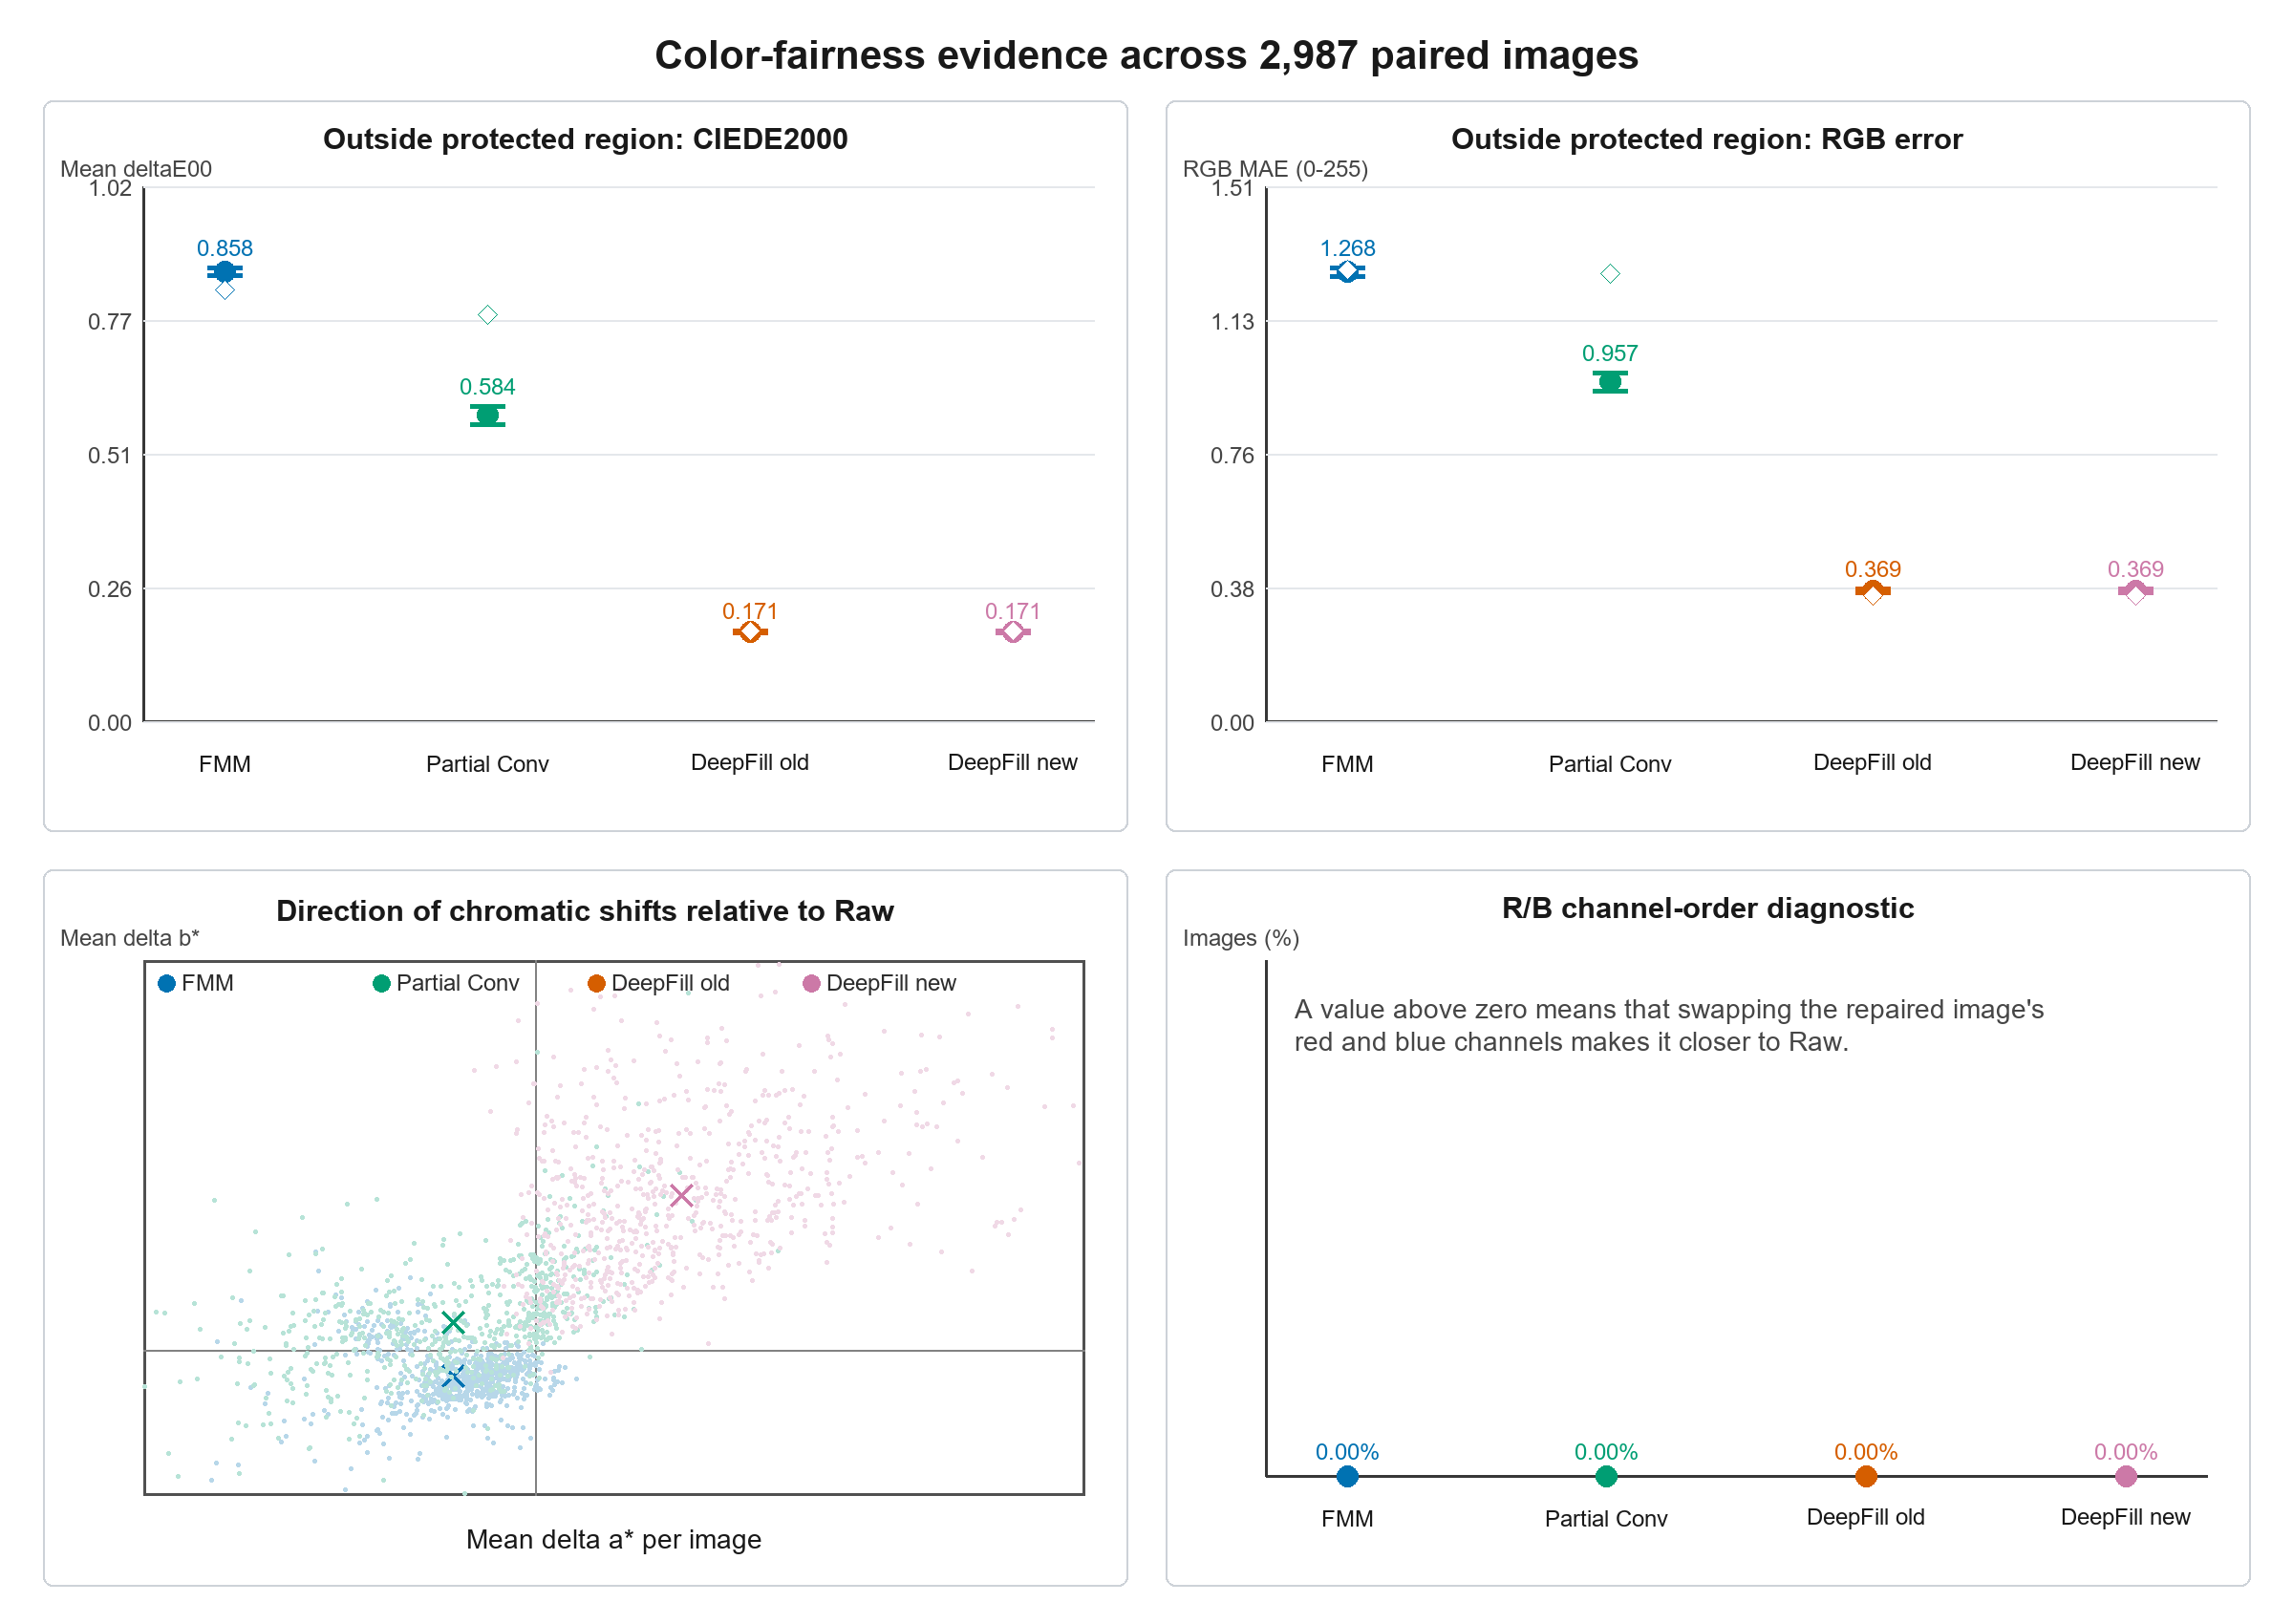

Saved: E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\outputs_deepfillv2_color_fairness_evidence\figures\color_fairness_evidence.png


In [7]:
def load_font(size, bold=False):
    candidates = [
        Path(r"C:\Windows\Fonts\arialbd.ttf" if bold else r"C:\Windows\Fonts\arial.ttf"),
        Path(r"C:\Windows\Fonts\calibrib.ttf" if bold else r"C:\Windows\Fonts\calibri.ttf"),
    ]
    for candidate in candidates:
        if candidate.is_file():
            return ImageFont.truetype(str(candidate), size=size)
    return ImageFont.load_default()


def hex_rgb(value):
    value = value.lstrip("#")
    return tuple(int(value[index:index+2], 16) for index in (0, 2, 4))


def pale_color(color, strength=0.28):
    return tuple(int(255 - (255-channel) * strength) for channel in color)


FONT_SMALL = load_font(24)
FONT_AXIS = load_font(28)
FONT_TITLE = load_font(31, bold=True)
FONT_HEADER = load_font(42, bold=True)
short_labels = ["FMM", "Partial Conv", "DeepFill old", "DeepFill new"]
colors = [hex_rgb(METHOD_COLORS[m]) for m in REPAIRED_METHODS]


def centered_text(draw, xy, text, font, fill=(25, 25, 25)):
    box = draw.textbbox((0, 0), text, font=font)
    draw.text((xy[0] - (box[2]-box[0])/2, xy[1] - (box[3]-box[1])/2),
              text, font=font, fill=fill)


def draw_panel_frame(draw, box, title):
    x0, y0, x1, y1 = box
    draw.rounded_rectangle(box, radius=10, outline=(205, 210, 216), width=2,
                           fill=(255, 255, 255))
    centered_text(draw, ((x0+x1)/2, y0+36), title, FONT_TITLE)


def draw_metric_panel(draw, box, mean_col, low_col, high_col, median_col,
                      ylabel):
    x0, y0, x1, y1 = box
    left, right = x0+105, x1-35
    top, bottom = y0+90, y1-115
    means = summary[mean_col].to_numpy(float)
    lows = summary[low_col].to_numpy(float)
    highs = summary[high_col].to_numpy(float)
    medians = summary[median_col].to_numpy(float)
    y_max = max(1e-6, float(np.max(highs)) * 1.18)
    draw.line((left, top, left, bottom), fill=(55, 55, 55), width=3)
    draw.line((left, bottom, right, bottom), fill=(55, 55, 55), width=3)
    for tick in np.linspace(0.0, y_max, 5):
        py = bottom - (tick / y_max) * (bottom-top)
        draw.line((left, py, right, py), fill=(228, 231, 235), width=2)
        label = "%.2f" % tick
        text_box = draw.textbbox((0, 0), label, font=FONT_SMALL)
        draw.text((left-12-(text_box[2]-text_box[0]), py-12), label,
                  font=FONT_SMALL, fill=(70, 70, 70))
    positions = np.linspace(left+85, right-85, len(short_labels))
    to_y = lambda value: bottom - (float(value) / y_max) * (bottom-top)
    for px, label, color, mean, low, high, median in zip(
        positions, short_labels, colors, means, lows, highs, medians
    ):
        y_mean, y_low, y_high, y_median = map(to_y, (mean, low, high, median))
        draw.line((px, y_high, px, y_low), fill=color, width=7)
        draw.line((px-18, y_high, px+18, y_high), fill=color, width=5)
        draw.line((px-18, y_low, px+18, y_low), fill=color, width=5)
        draw.ellipse((px-11, y_mean-11, px+11, y_mean+11), fill=color)
        draw.polygon([(px, y_median-10), (px+10, y_median),
                      (px, y_median+10), (px-10, y_median)],
                     fill=(255, 255, 255), outline=color)
        centered_text(draw, (px, bottom+40), label, FONT_SMALL)
        centered_text(draw, (px, y_high-26), "%.3f" % mean, FONT_SMALL,
                      fill=color)
    draw.text((x0+18, y0+58), ylabel, font=FONT_SMALL,
              fill=(70, 70, 70))


canvas = PILImage.new("RGB", (2400, 1700), "white")
draw = ImageDraw.Draw(canvas)
centered_text(
    draw, (1200, 52),
    "Color-fairness evidence across %s paired images" % f"{len(ANALYSIS_NAMES):,}",
    FONT_HEADER,
)
panel_boxes = [
    (45, 105, 1180, 870), (1220, 105, 2355, 870),
    (45, 910, 1180, 1660), (1220, 910, 2355, 1660),
]
draw_panel_frame(draw, panel_boxes[0],
                 "Outside protected region: CIEDE2000")
draw_metric_panel(
    draw, panel_boxes[0], "deltae00_mean", "deltae00_ci95_low",
    "deltae00_ci95_high", "deltae00_median", "Mean deltaE00",
)
draw_panel_frame(draw, panel_boxes[1],
                 "Outside protected region: RGB error")
draw_metric_panel(
    draw, panel_boxes[1], "rgb_mae_mean", "rgb_mae_ci95_low",
    "rgb_mae_ci95_high", "rgb_mae_median", "RGB MAE (0-255)",
)

# Lab chromatic-shift panel.
box = panel_boxes[2]
draw_panel_frame(draw, box, "Direction of chromatic shifts relative to Raw")
x0, y0, x1, y1 = box
left, right, top, bottom = x0+105, x1-45, y0+95, y1-95
all_a = metrics.outside_delta_a.to_numpy(float)
all_b = metrics.outside_delta_b.to_numpy(float)
a_min = min(float(np.percentile(all_a, 1)), 0.0)
a_max = max(float(np.percentile(all_a, 99)), 0.0)
b_min = min(float(np.percentile(all_b, 1)), 0.0)
b_max = max(float(np.percentile(all_b, 99)), 0.0)
if a_max <= a_min:
    a_min, a_max = -1.0, 1.0
if b_max <= b_min:
    b_min, b_max = -1.0, 1.0
a_pad, b_pad = 0.12*(a_max-a_min), 0.12*(b_max-b_min)
a_min, a_max = a_min-a_pad, a_max+a_pad
b_min, b_max = b_min-b_pad, b_max+b_pad
to_x = lambda value: left + (float(value)-a_min)/(a_max-a_min)*(right-left)
to_y = lambda value: bottom - (float(value)-b_min)/(b_max-b_min)*(bottom-top)
draw.rectangle((left, top, right, bottom), outline=(80, 80, 80), width=3)
if a_min <= 0 <= a_max:
    draw.line((to_x(0), top, to_x(0), bottom), fill=(130, 130, 130), width=2)
if b_min <= 0 <= b_max:
    draw.line((left, to_y(0), right, to_y(0)), fill=(130, 130, 130), width=2)
for method, label, color in zip(REPAIRED_METHODS, short_labels, colors):
    subset = metrics.loc[metrics.method == method]
    sample_count = min(700, len(subset))
    sample_indices = np.linspace(0, len(subset)-1, sample_count, dtype=int)
    point_color = pale_color(color)
    for row in subset.iloc[sample_indices].itertuples():
        if a_min <= row.outside_delta_a <= a_max and b_min <= row.outside_delta_b <= b_max:
            px, py = to_x(row.outside_delta_a), to_y(row.outside_delta_b)
            draw.ellipse((px-2, py-2, px+2, py+2), fill=point_color)
    mx = to_x(subset.outside_delta_a.mean())
    my = to_y(subset.outside_delta_b.mean())
    draw.line((mx-11, my-11, mx+11, my+11), fill=color, width=5)
    draw.line((mx-11, my+11, mx+11, my-11), fill=color, width=5)
centered_text(draw, ((left+right)/2, bottom+43), "Mean delta a* per image", FONT_AXIS)
draw.text((x0+18, y0+58), "Mean delta b*", font=FONT_SMALL,
          fill=(70, 70, 70))
legend_x = left+15
for label, color in zip(short_labels, colors):
    draw.ellipse((legend_x, top+15, legend_x+18, top+33), fill=color)
    draw.text((legend_x+25, top+10), label, font=FONT_SMALL, fill=(45, 45, 45))
    legend_x += 225

# R/B channel-order diagnostic panel.
box = panel_boxes[3]
draw_panel_frame(draw, box, "R/B channel-order diagnostic")
x0, y0, x1, y1 = box
left, right, top, bottom = x0+105, x1-45, y0+95, y1-115
swap_percent = summary.rb_swap_better_fraction.to_numpy(float) * 100.0
y_max = max(1.0, float(np.max(swap_percent)) * 1.18)
draw.line((left, top, left, bottom), fill=(55, 55, 55), width=3)
draw.line((left, bottom, right, bottom), fill=(55, 55, 55), width=3)
positions = np.linspace(left+85, right-85, len(short_labels))
for px, label, color, value in zip(positions, short_labels, colors, swap_percent):
    py = bottom - (value/y_max)*(bottom-top)
    draw.line((px, bottom, px, py), fill=color, width=9)
    draw.ellipse((px-11, py-11, px+11, py+11), fill=color)
    centered_text(draw, (px, py-30), "%.2f%%" % value, FONT_SMALL,
                  fill=color)
    centered_text(draw, (px, bottom+40), label, FONT_SMALL)
draw.text((x0+18, y0+58), "Images (%)", font=FONT_SMALL,
          fill=(70, 70, 70))
draw.multiline_text(
    (left+30, top+35),
    "A value above zero means that swapping the repaired image's\n"
    "red and blue channels makes it closer to Raw.",
    font=FONT_AXIS, fill=(70, 70, 70), spacing=8,
)

evidence_figure = FIGURE_DIR / "color_fairness_evidence.png"
canvas.save(evidence_figure, dpi=(FIGURE_DPI, FIGURE_DPI))
if SHOW_FIGURES:
    display(IPythonImage(filename=str(evidence_figure)))
print("Saved:", evidence_figure)

## 7. Objectively selected qualitative cases

Cases are selected from the new DeepFill v2 outside-mask CIEDE2000 distribution: nearest to the median, nearest to the 95th percentile, and maximum. No cyan contours or color overlays are drawn on the images.

,selection,image_name,deepfill_new_outside_deltae00_mean
0,Case 1,39,0.166431
1,Case 2,c1_100h0050 (116),0.171149
2,Case 3,c3_endocv2021_001 (181),0.146857


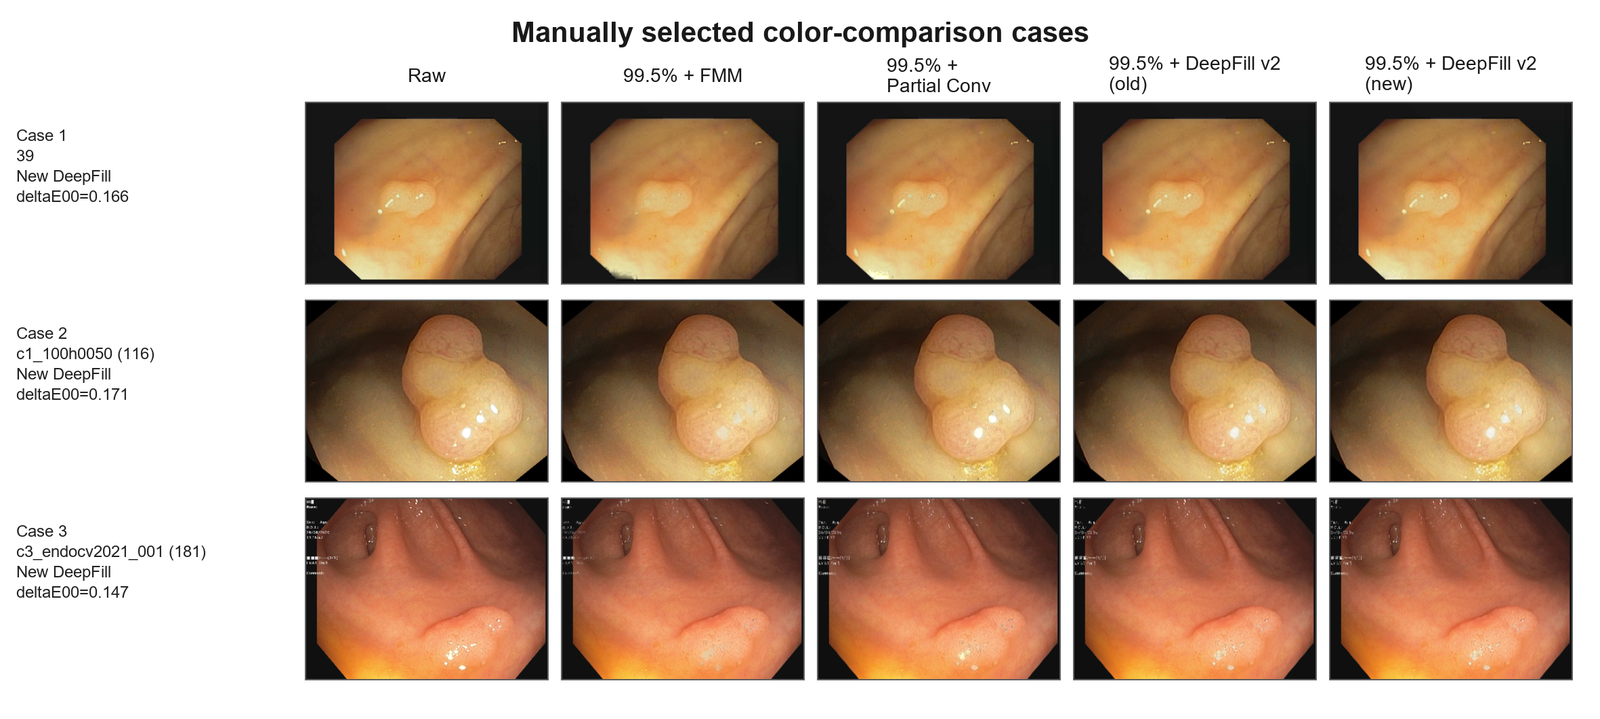

Saved: E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\outputs_deepfillv2_color_fairness_evidence\figures\representative_cases_manual.png


In [8]:
# ============================================================
# 手动选择代表性图片并生成对比图
# 依赖前面Cell已生成：
# metrics, IMAGE_MAPS, REPAIRED_METHODS, OUTPUT_DIR, FIGURE_DIR
# read_bgr, bgr_to_rgb, COMMON_DISPLAY_SIZE
# centered_text, FONT_HEADER, FONT_AXIS, FONT_SMALL
# ============================================================

from pathlib import Path

import cv2
import pandas as pd
from IPython.display import Image as IPythonImage, display
from PIL import Image as PILImage, ImageDraw


# ------------------------------------------------------------
# 1. 在这里填写希望展示的图片
#
# 格式：
# ("图中显示的案例名称", "图片文件名或文件名主干")
#
# 可以填写扩展名，也可以不填写。
# 可以增加或删除图片，画布高度会自动调整。
# ------------------------------------------------------------
MANUAL_CASES = [
    ("Case 1", "39.jpg"),
    ("Case 2", "c1_100H0050 (116).jpg"),
    ("Case 3", "C3_EndoCV2021_001 (181).jpg"),
]


# ------------------------------------------------------------
# 2. 整理DeepFill v2新版本的逐图指标
# ------------------------------------------------------------
deepfill_new_metrics = (
    metrics.loc[metrics.method == "deepfill_new"]
    .sort_values(
        ["outside_deltae00_mean", "image_name"],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

deepfill_metric_lookup = (
    deepfill_new_metrics
    .set_index("image_name", drop=False)
)


def normalize_manual_image_name(value):
    """
    将完整路径、带扩展名文件名或文件名主干统一转换为IMAGE_MAPS使用的键。
    """
    filename = Path(str(value)).name
    suffix = Path(filename).suffix.casefold()

    if suffix in IMAGE_EXTENSIONS:
        filename = Path(filename).stem

    return filename.casefold()


selected_rows = []
seen_names = set()

for case_label, filename in MANUAL_CASES:
    image_name = normalize_manual_image_name(filename)

    if image_name in seen_names:
        raise ValueError(f"重复选择了同一幅图片：{filename}")
    seen_names.add(image_name)

    # 检查Raw及所有修复方法中是否均存在该图片
    missing_methods = [
        method
        for method, image_map in IMAGE_MAPS.items()
        if image_name not in image_map
    ]

    if missing_methods:
        raise ValueError(
            f"图片 {filename} 在以下方法中不存在：{missing_methods}"
        )

    if image_name not in deepfill_metric_lookup.index:
        raise ValueError(
            f"在DeepFill v2逐图指标中找不到图片：{filename}"
        )

    metric_row = deepfill_metric_lookup.loc[image_name]

    selected_rows.append({
        "selection": case_label,
        "image_name": image_name,
        "deepfill_new_outside_deltae00_mean":
            float(metric_row.outside_deltae00_mean),
    })


representative_selection = pd.DataFrame(selected_rows)

if representative_selection.empty:
    raise ValueError("MANUAL_CASES不能为空。")

representative_selection.to_csv(
    OUTPUT_DIR / "representative_selection.csv",
    index=False,
)

display(representative_selection)


# ------------------------------------------------------------
# 3. 图像列标题
# ------------------------------------------------------------
display_labels = [
    "Raw",
    "99.5% + FMM",
    "99.5% +\nPartial Conv",
    "99.5% + DeepFill v2\n(old)",
    "99.5% + DeepFill v2\n(new)",
]


# ------------------------------------------------------------
# 4. 动态画布尺寸
# ------------------------------------------------------------
label_width = 450
cell_width, cell_height = 360, 270
column_gap, row_gap = 18, 22
header_height = 150
row_height = cell_height + row_gap

number_of_rows = len(representative_selection)
number_of_columns = len(display_labels)

canvas_width = (
    label_width
    + number_of_columns * cell_width
    + (number_of_columns - 1) * column_gap
    + 40
)

canvas_height = (
    header_height
    + number_of_rows * row_height
    + 35
)

montage = PILImage.new(
    "RGB",
    (canvas_width, canvas_height),
    "white",
)

montage_draw = ImageDraw.Draw(montage)


# ------------------------------------------------------------
# 5. 绘制总标题和列标题
# ------------------------------------------------------------
centered_text(
    montage_draw,
    (canvas_width / 2, 42),
    "Manually selected color-comparison cases",
    FONT_HEADER,
)

for column_index, label in enumerate(display_labels):
    x_center = (
        label_width
        + column_index * (cell_width + column_gap)
        + cell_width / 2
    )

    centered_text(
        montage_draw,
        (x_center, 105),
        label,
        FONT_AXIS,
    )


# ------------------------------------------------------------
# 6. 读取并绘制每个案例
# ------------------------------------------------------------
for row_index, record in representative_selection.iterrows():
    image_name = record.image_name

    raw_original = read_bgr(
        IMAGE_MAPS["raw"][image_name]
    )

    images = [
        cv2.resize(
            raw_original,
            COMMON_DISPLAY_SIZE,
            interpolation=cv2.INTER_LINEAR,
        )
    ]

    for method in REPAIRED_METHODS:
        source = read_bgr(
            IMAGE_MAPS[method][image_name]
        )

        resized = cv2.resize(
            source,
            COMMON_DISPLAY_SIZE,
            interpolation=cv2.INTER_LINEAR,
        )

        images.append(resized)

    y = header_height + row_index * row_height

    # 对较长文件名进行自动换行
    display_name = str(image_name)

    if len(display_name) > 46:
        display_name = display_name[:43] + "..."

    display_name = "\n".join(
        display_name[index:index + 23]
        for index in range(0, len(display_name), 23)
    )

    row_text = (
        f"{record.selection}\n"
        f"{display_name}\n"
        f"New DeepFill\n"
        f"deltaE00="
        f"{record.deepfill_new_outside_deltae00_mean:.3f}"
    )

    montage_draw.multiline_text(
        (24, y + 36),
        row_text,
        font=FONT_SMALL,
        fill=(35, 35, 35),
        spacing=8,
    )

    for column_index, image_bgr in enumerate(images):
        x = (
            label_width
            + column_index * (cell_width + column_gap)
        )

        image_pil = PILImage.fromarray(
            bgr_to_rgb(image_bgr)
        ).resize(
            (cell_width, cell_height),
            PILImage.Resampling.BILINEAR,
        )

        montage.paste(image_pil, (x, y))

        montage_draw.rectangle(
            (
                x,
                y,
                x + cell_width - 1,
                y + cell_height - 1,
            ),
            outline=(95, 95, 95),
            width=2,
        )


# ------------------------------------------------------------
# 7. 保存并强制在Notebook中显示
# ------------------------------------------------------------
from IPython.display import display

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

representative_figure = (
    FIGURE_DIR / "representative_cases_manual.png"
)

# 保存原始高分辨率图片
montage.save(
    representative_figure,
    dpi=(FIGURE_DPI, FIGURE_DPI),
)

# 生成适合Notebook页面显示的预览图
preview = montage.copy()
preview.thumbnail((1600, 2000), PILImage.Resampling.LANCZOS)

# 强制内嵌显示，不受SHOW_FIGURES影响
display(preview)

print("Saved:", representative_figure)

## 8. Export a compact hand-off summary

`results_to_send.md` contains the values needed for drafting the reviewer response. The output deliberately distinguishes global color preservation from the unknown reconstruction accuracy inside the highlight mask.

In [10]:
# ============================================================
# 导出环境、配置、结果摘要，并检查所有输出文件
# 适用于手动选择代表图片的版本
# ============================================================

import json
import platform
import sys

from IPython.display import Markdown, display


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. 整理手动选择的代表案例
# ------------------------------------------------------------
representative_cases_config = [
    {
        "selection": str(row.selection),
        "image_name": str(row.image_name),
        "deepfill_new_outside_deltae00_mean": float(
            row.deepfill_new_outside_deltae00_mean
        ),
    }
    for row in representative_selection.itertuples(index=False)
]

if not representative_cases_config:
    raise ValueError(
        "representative_selection为空。请先运行手动选图Cell。"
    )


# ------------------------------------------------------------
# 2. 保存运行环境
# ------------------------------------------------------------
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    **REQUIRED_MODULES,
}

environment_path = OUTPUT_DIR / "environment.json"

with open(environment_path, "w", encoding="utf-8") as file:
    json.dump(
        environment,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 3. 保存分析配置
# ------------------------------------------------------------
config = {
    "formal_full_analysis": MAX_IMAGES is None,
    "paired_images_available": len(ALL_NAMES),
    "paired_images_processed": len(ANALYSIS_NAMES),
    "percentile": PERCENTILE,
    "protection_radius": PROTECTION_RADIUS,
    "learning_size": list(LEARNING_SIZE),
    "fmm_output_size": list(FMM_OUTPUT_SIZE),

    "methods": {
        method: str(path)
        for method, path in METHOD_DIRS.items()
    },

    "representative_selection_mode": "manual",
    "representative_cases": representative_cases_config,

    "representative_figure": (
        "figures/representative_cases_manual.png"
    ),

    "note": (
        "FMM was saved as JPEG whereas the learning-based outputs "
        "were saved primarily as PNG. Metrics describe each complete "
        "evaluated output pipeline."
    ),
}

config_path = OUTPUT_DIR / "analysis_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        config,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 4. 创建Markdown结果摘要
# ------------------------------------------------------------
lines = [
    "# DeepFill v2 color-fairness results",
    "",
    f"- Formal full analysis: "
    f"{'yes' if MAX_IMAGES is None else 'no'}",
    f"- Strictly paired images available: {len(ALL_NAMES)}",
    f"- Images processed in this run: {len(ANALYSIS_NAMES)}",
    (
        f"- Analysis excludes the {PERCENTILE}% highlight mask "
        f"and a {PROTECTION_RADIUS}-pixel protection band."
    ),
    "- Representative case selection: manual",
    "",
    "## Outside-mask color preservation",
    "",
    (
        "| Method | Mean deltaE00 (95% CI) | "
        "Median deltaE00 [IQR] | RGB MAE | "
        "Mean deltaL* | Mean deltaa* | Mean deltab* | "
        "R/B-swap better |"
    ),
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]


# ------------------------------------------------------------
# 5. 添加各方法颜色统计
# ------------------------------------------------------------
for row in summary.itertuples(index=False):
    lines.append(
        "| %s | %.4f [%.4f, %.4f] | "
        "%.4f [%.4f, %.4f] | %.4f | "
        "%.4f | %.4f | %.4f | %d/%d |"
        % (
            row.method_label,
            float(row.deltae00_mean),
            float(row.deltae00_ci95_low),
            float(row.deltae00_ci95_high),
            float(row.deltae00_median),
            float(row.deltae00_q1),
            float(row.deltae00_q3),
            float(row.rgb_mae_mean),
            float(row.delta_L_mean),
            float(row.delta_a_mean),
            float(row.delta_b_mean),
            int(row.rb_swap_better_count),
            int(row.n),
        )
    )


# ------------------------------------------------------------
# 6. 添加DeepFill新旧版本一致性结果
# ------------------------------------------------------------
consistency = old_new_summary.iloc[0]

lines.extend([
    "",
    "## DeepFill old/new consistency",
    "",
    (
        "- Pixel-identical images: %d/%d (%.2f%%)"
        % (
            int(consistency.pixel_identical_count),
            int(consistency.n),
            100.0 * float(
                consistency.pixel_identical_fraction
            ),
        )
    ),
    (
        "- Mean pixel MAE: %.8f on the 0-255 scale"
        % float(consistency.mean_pixel_mae)
    ),
    (
        "- Maximum per-image pixel MAE: %.8f"
        % float(consistency.maximum_pixel_mae)
    ),
    (
        "- Maximum single-channel absolute difference: %d"
        % int(consistency.maximum_channel_abs_diff)
    ),
    (
        "- Mean changed-pixel fraction: %.8f"
        % float(consistency.mean_changed_pixel_fraction)
    ),
])


# ------------------------------------------------------------
# 7. 添加手动选择的代表图片信息
# ------------------------------------------------------------
lines.extend([
    "",
    "## Manually selected representative cases",
    "",
    "| Label | Image name | New DeepFill mean deltaE00 |",
    "|---|---|---:|",
])

for case in representative_cases_config:
    lines.append(
        "| %s | `%s` | %.4f |"
        % (
            case["selection"],
            case["image_name"],
            case[
                "deepfill_new_outside_deltae00_mean"
            ],
        )
    )


# ------------------------------------------------------------
# 8. 添加解释边界和文件列表
# ------------------------------------------------------------
lines.extend([
    "",
    "## Interpretation boundary",
    "",
    (
        "These measurements test whether the evaluated output "
        "pipeline introduces a whole-image color shift outside "
        "the repaired region. They do not establish anatomical "
        "correctness of synthesized pixels inside the highlight mask."
    ),
    "",
    (
        "FMM images are JPEG files while the learning-based outputs "
        "are primarily PNG files. Cross-method differences therefore "
        "describe the complete stored-image pipelines and should not "
        "be interpreted as a pure ranking of inpainting algorithms."
    ),
    "",
    (
        "The representative cases in the qualitative figure were "
        "manually selected. Quantitative conclusions are based on "
        "all paired images, not only these displayed examples."
    ),
    "",
    "## Files",
    "",
    "- `color_fairness_summary.csv`",
    "- `per_image_color_metrics.csv`",
    "- `deepfill_old_new_consistency.csv`",
    "- `deepfill_old_new_summary.csv`",
    "- `representative_selection.csv`",
    "- `figures/color_fairness_evidence.png`",
    "- `figures/representative_cases_manual.png`",
])


# ------------------------------------------------------------
# 9. 保存Markdown摘要
# ------------------------------------------------------------
results_path = OUTPUT_DIR / "results_to_send.md"

with open(results_path, "w", encoding="utf-8") as file:
    file.write("\n".join(lines) + "\n")


# ------------------------------------------------------------
# 10. 检查表格和配置文件
# ------------------------------------------------------------
required_outputs = [
    "color_fairness_summary.csv",
    "per_image_color_metrics.csv",
    "deepfill_old_new_consistency.csv",
    "deepfill_old_new_summary.csv",
    "representative_selection.csv",
    "results_to_send.md",
    "analysis_config.json",
    "environment.json",
]

missing_outputs = [
    name
    for name in required_outputs
    if not (OUTPUT_DIR / name).is_file()
]

if missing_outputs:
    raise AssertionError(
        "Missing outputs: %s" % missing_outputs
    )


# ------------------------------------------------------------
# 11. 检查图片文件
# ------------------------------------------------------------
required_figures = [
    "color_fairness_evidence.png",
    "representative_cases_manual.png",
]

missing_figures = [
    name
    for name in required_figures
    if not (FIGURE_DIR / name).is_file()
]

if missing_figures:
    raise AssertionError(
        "Missing figures: %s" % missing_figures
    )


# ------------------------------------------------------------
# 12. 在Notebook内显示最终Markdown摘要
# ------------------------------------------------------------
display(
    Markdown(
        "\n".join(lines)
    )
)

print("Analysis complete.")
print("Reviewer-response summary:")
print(results_path)
print("Manual representative figure:")
print(FIGURE_DIR / "representative_cases_manual.png")

# DeepFill v2 color-fairness results

- Formal full analysis: yes
- Strictly paired images available: 2987
- Images processed in this run: 2987
- Analysis excludes the 99.5% highlight mask and a 3-pixel protection band.
- Representative case selection: manual

## Outside-mask color preservation

| Method | Mean deltaE00 (95% CI) | Median deltaE00 [IQR] | RGB MAE | Mean deltaL* | Mean deltaa* | Mean deltab* | R/B-swap better |
|---|---:|---:|---:|---:|---:|---:|---:|
| 99.5% + FMM | 0.8582 [0.8507, 0.8657] | 0.8227 [0.7309, 0.9230] | 1.2680 | -0.0140 | -0.0350 | -0.0242 | 0/2987 |
| 99.5% + Partial Conv | 0.5842 [0.5666, 0.6018] | 0.7757 [0.1011, 0.9880] | 0.9574 | -0.0793 | -0.0353 | 0.0263 | 0/2987 |
| 99.5% + DeepFill v2 (old) | 0.1706 [0.1687, 0.1725] | 0.1716 [0.1316, 0.2106] | 0.3692 | -0.1165 | 0.0623 | 0.1473 | 0/2987 |
| 99.5% + DeepFill v2 (new) | 0.1706 [0.1687, 0.1725] | 0.1716 [0.1316, 0.2106] | 0.3692 | -0.1165 | 0.0623 | 0.1473 | 0/2987 |

## DeepFill old/new consistency

- Pixel-identical images: 212/2987 (7.10%)
- Mean pixel MAE: 0.00011117 on the 0-255 scale
- Maximum per-image pixel MAE: 0.00049506
- Maximum single-channel absolute difference: 2
- Mean changed-pixel fraction: 0.00031508

## Manually selected representative cases

| Label | Image name | New DeepFill mean deltaE00 |
|---|---|---:|
| Case 1 | `39` | 0.1664 |
| Case 2 | `c1_100h0050 (116)` | 0.1711 |
| Case 3 | `c3_endocv2021_001 (181)` | 0.1469 |

## Interpretation boundary

These measurements test whether the evaluated output pipeline introduces a whole-image color shift outside the repaired region. They do not establish anatomical correctness of synthesized pixels inside the highlight mask.

FMM images are JPEG files while the learning-based outputs are primarily PNG files. Cross-method differences therefore describe the complete stored-image pipelines and should not be interpreted as a pure ranking of inpainting algorithms.

The representative cases in the qualitative figure were manually selected. Quantitative conclusions are based on all paired images, not only these displayed examples.

## Files

- `color_fairness_summary.csv`
- `per_image_color_metrics.csv`
- `deepfill_old_new_consistency.csv`
- `deepfill_old_new_summary.csv`
- `representative_selection.csv`
- `figures/color_fairness_evidence.png`
- `figures/representative_cases_manual.png`

Analysis complete.
Reviewer-response summary:
E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\outputs_deepfillv2_color_fairness_evidence\results_to_send.md
Manual representative figure:
E:\project\1.工作1\0.投稿\3.pattern recognition (再修)\Major Revision\code_supplement\outputs_deepfillv2_color_fairness_evidence\figures\representative_cases_manual.png
